TASK 1: Load and Understand the Dataset

Load the student placement dataset and carefully examine the available information.

Display the first few records, last few records, and random samples from the dataset.

Identify the total number of students and the total number of columns available.

Study each column and determine whether it represents academic performance,
technical ability, career preparation, personal development, or placement outcome.

Identify the target variable and explain why it is the most important column for this
prediction problem.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from google.colab import files
import io

print("Please upload 'student_placement_prediction_dataset_2026.xlsx':")
uploaded = files.upload()
if uploaded:
    filename = next(iter(uploaded))
    print(f"\nSuccessfully uploaded: {filename}")
    df = pd.read_excel(io.BytesIO(uploaded[filename]))

    print("\nFirst 5 Records:")
    print(df.head())
    print("\nLast 5 Records:")
    print(df.tail())
    print("\n5 Random Records:")
    print(df.sample(n=5, random_state=42))

    print("\nDataset Dimensions:")
    print("Total Students:", df.shape[0])
    print("Total Columns:", df.shape[1])

    print("\nDataset Information:")
    df.info()
else:
    print("No file uploaded. Please run the cell again and upload your dataset file.")

Please upload 'student_placement_prediction_dataset_2026.xlsx':


Saving student_placement_prediction_dataset_2026.xlsx to student_placement_prediction_dataset_2026 (1).xlsx

Successfully uploaded: student_placement_prediction_dataset_2026 (1).xlsx

First 5 Records:
   student_id  age  gender  cgpa branch college_tier  internships_count  \
0           1   24    Male  7.53     IT       Tier 2                  4   
1           2   21    Male  7.92    CSE       Tier 2                  1   
2           3   22  Female  8.60    EEE       Tier 1                  0   
3           4   24    Male  6.68    CSE       Tier 1                  0   
4           5   20  Female  8.43     IT       Tier 3                  1   

   projects_count  certifications_count  coding_skill_score  ...  \
0               6                     1           99.238568  ...   
1               3                     6           80.966123  ...   
2               1                     1           49.177184  ...   
3               2                     2           79.359084  ...   
4       

TASK 2: Basic Data Inspection

Perform a complete inspection of the dataset. Check the dataset dimensions, column
names, data types, unique values, missing values, duplicate records, and summary
statistics of numerical columns.

Analyze the distribution of the placement_status
column and determine how many students are placed and how many are not placed.

Also investigate whether the target classes are balanced or imbalanced and explain
why this information is important before selecting and training a Machine Learning
model.

In [ ]:
print("Dataset Dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nUnique Values:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nNumerical Summary Statistics:", df.describe().T.round(2))

print("\nPlacement Distribution Status:")
counts = df["placement_status"].value_counts()
percentages = df["placement_status"].value_counts(normalize=True) * 100
distribution = pd.DataFrame({
    "Student Count": counts,
    "Percentage": percentages.round(2)
})
print(distribution)
placed = counts.get("Placed", 0)
not_placed = counts.get("Not Placed", 0)

print("\nClass Balance:")
print("Placed students:", placed)
print("Not placed students:", not_placed)
if min(placed, not_placed) > 0:
    print("Majority-to-minority ratio:",
          round(max(placed, not_placed) /
                min(placed, not_placed), 2))
    if min(placed, not_placed) / max(placed, not_placed) >= 0.8:
        print("The classes are reasonably balanced.")
    else:
        print("The classes are imbalanced.")


Dataset Dimensions:
Rows: 100000
Columns: 26

Column names:
['student_id', 'age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day', 'placement_status', 'salary_package_lpa']

Data Types:
student_id                     int64
age                            int64
gender                        object
cgpa                         float64
branch                        object
college_tier                  object
internships_count              int64
projects_count                 int64
certifications_count           int64
coding_skill_score           float64
aptitude_score               float64
communication_skil

TASK 3: Data Cleaning and Preprocessing

Clean the dataset before applying Machine Learning algorithms. Remove student_id
because it is only an identification number and does not provide meaningful
predictive information.

Remove salary_package_lpa from the placement prediction
features because salary is an outcome that becomes known after placement and
using it could result in data leakage.

Check for missing values, duplicate records,
incorrect data types, and unusual observations. Decide how missing or inconsistent
values should be handled and explain the reasoning behind your decisions.

In [ ]:
df_clean = df.copy()
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

df_clean.drop(
    columns=["student_id", "salary_package_lpa"],
    inplace=True,
    errors="raise")
print("Columns removed: student_id, salary_package_lpa")
print("Shape after removal:", df_clean.shape)
print("Remaining columns:", df_clean.columns.tolist())

missing_before = df_clean.isnull().sum()
print("Missing values in each column:", missing_before[missing_before > 0])
print("Total missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().copy()
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("Shape after duplicate removal:", df_clean.shape)

categorical_columns = [
    "gender", "branch", "college_tier",
    "volunteer_experience", "placement_status"]
for col in categorical_columns:
    df_clean[col] = (df_clean[col]
                     .astype("string")
                     .str.strip())
numerical_columns = ["age", "cgpa", "internships_count",
                     "projects_count", "certifications_count",
                     "coding_skill_score", "aptitude_score",
                     "communication_skill_score",
                     "logical_reasoning_score",
                     "hackathons_participated", "github_repos",
                     "linkedin_connections", "mock_interview_score",
                     "attendance_percentage", "backlogs",
                     "extracurricular_score", "leadership_score",
                     "sleep_hours", "study_hours_per_day"]
for col in numerical_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
print("\nCategorical values after standardization:")
for col in categorical_columns:
    print(col, df_clean[col].unique())

valid_ranges = {"age": (16, 100),
                "cgpa": (0, 10),
                "coding_skill_score": (0, 100),
                "aptitude_score": (0, 100),
                "communication_skill_score": (0, 100),
                "logical_reasoning_score": (0, 100),
                "mock_interview_score": (0, 100),
                "attendance_percentage": (0, 100),
                "extracurricular_score": (0, 100),
                "leadership_score": (0, 100),
                "sleep_hours": (0, 24),
                "study_hours_per_day": (0, 24)}
for col, (lower, upper) in valid_ranges.items():
    invalid = ((df_clean[col] < lower) | (df_clean[col] > upper))
    print(f"{col}: {invalid.sum()} invalid values")
    df_clean.loc[invalid, col] = np.nan
count_columns = ["internships_count", "projects_count",
                 "certifications_count", "hackathons_participated",
                 "github_repos", "linkedin_connections", "backlogs"]
for col in count_columns:
    invalid = df_clean[col] < 0
    print(f"{col}: {(invalid).sum()} invalid values")
    df_clean.loc[invalid, col] = np.nan
outlier_summary = {}
for col in numerical_columns:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = ((df_clean[col] < lower) | (df_clean[col] > upper))
    outlier_summary[col] = outliers.sum()
outlier_summary = pd.Series(
    outlier_summary,
    name="Outlier Count"
).sort_values(ascending=False)
print("Potential statistical outliers:")
print(outlier_summary)

allowed_categories = {"gender": ["Male", "Female"],
                      "branch": ["CSE", "ECE", "EEE", "Civil","Mechanical", "IT"],
                      "college_tier": ["Tier 1", "Tier 2", "Tier 3"],
                      "volunteer_experience": ["Yes", "No"],
                      "placement_status": ["Placed", "Not Placed"]}
for col, allowed in allowed_categories.items():
    invalid = ~df_clean[col].isin(allowed)
    print(f"{col}: {invalid.sum()} unexpected categories")
    df_clean.loc[invalid, col] = pd.NA
df_clean = df_clean.dropna(subset=["placement_status"]).copy()
all_missing = df_clean.columns[df_clean.isna().all()].tolist()
if all_missing:
    print("Dropping entirely missing columns:", all_missing)
    df_clean.drop(columns=all_missing, inplace=True)
for col in numerical_columns:
    if col in df_clean.columns:
        if df_clean[col].isna().any():
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in categorical_columns:
    if col in df_clean.columns:
        if df_clean[col].isna().any():
            mode_values = df_clean[col].mode(dropna=True)
            if not mode_values.empty:
                df_clean[col] = df_clean[col].fillna(
                    mode_values.iloc[0])
print("\nMissing values after cleaning:", df_clean.isnull().sum().sum())
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("Final shape:", df_clean.shape)
print("\nFinal data types:", df_clean.dtypes)
print("\nTarget distribution after cleaning:", df_clean["placement_status"].value_counts())

Original dataset shape: (100000, 26)
Working dataset shape: (100000, 26)
Columns removed: student_id, salary_package_lpa
Shape after removal: (100000, 24)
Remaining columns: ['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'aptitude_score', 'communication_skill_score', 'logical_reasoning_score', 'hackathons_participated', 'github_repos', 'linkedin_connections', 'mock_interview_score', 'attendance_percentage', 'backlogs', 'extracurricular_score', 'leadership_score', 'volunteer_experience', 'sleep_hours', 'study_hours_per_day', 'placement_status']
Missing values in each column: Series([], dtype: int64)
Total missing values: 0
Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Shape after duplicate removal: (100000, 24)

Categorical values after standardization:
gender <StringArray>
['Male', 'Female']
Length: 2, dtype: string
branch <StringArray>
['IT', 'CSE', 'EEE', 'Civil', 'Mechanica

TASK 4: Exploratory Data Analysis

Perform exploratory analysis to understand the factors associated with student
placement.Analyze the relationship between CGPA and placement status, internship
experience and placement status, number of projects and placement status, coding skill and placement status, aptitude score and placement status, communication skill and placement status, logical reasoning score and placement status, mock interview
score and placement status, attendance percentage and placement status, and backlogs and placement status.

Also investigate whether college tier, branch,
certifications, hackathons, GitHub repositories, and leadership activities appear to influence placement outcomes. Use appropriate charts and explain the important patterns discovered from the data.

Dataset shape: (100000, 26)

Placement distribution: placement_status
Placed        54459
Not Placed    45541
Name: count, dtype: int64


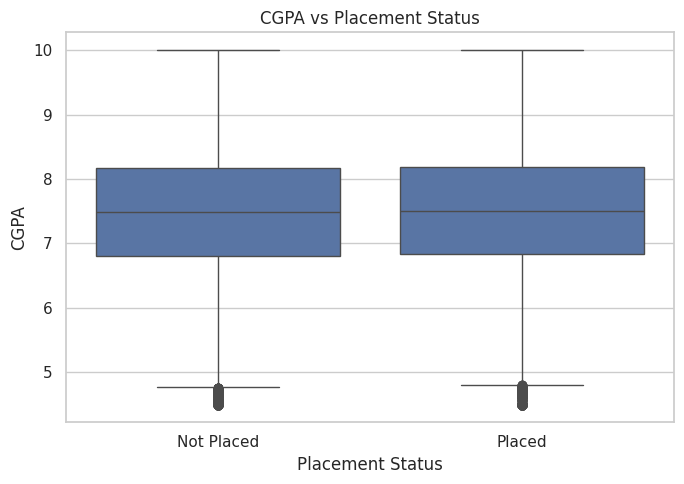

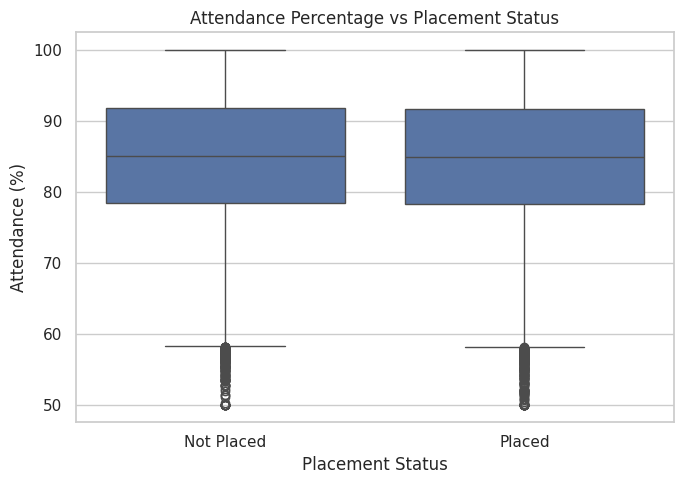

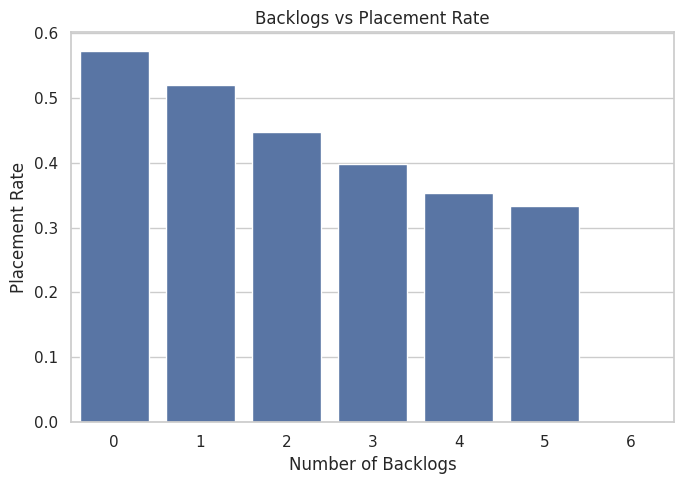

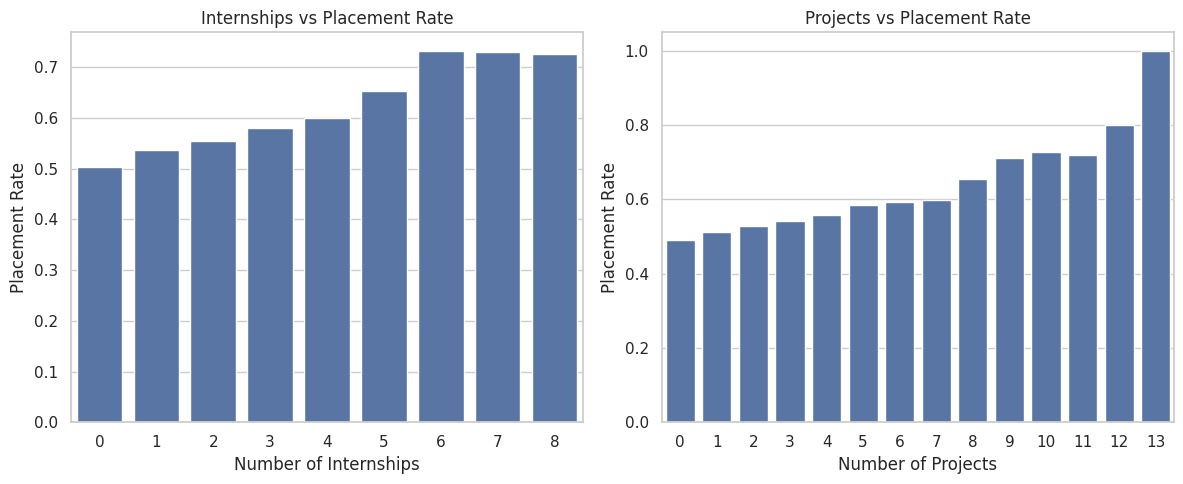

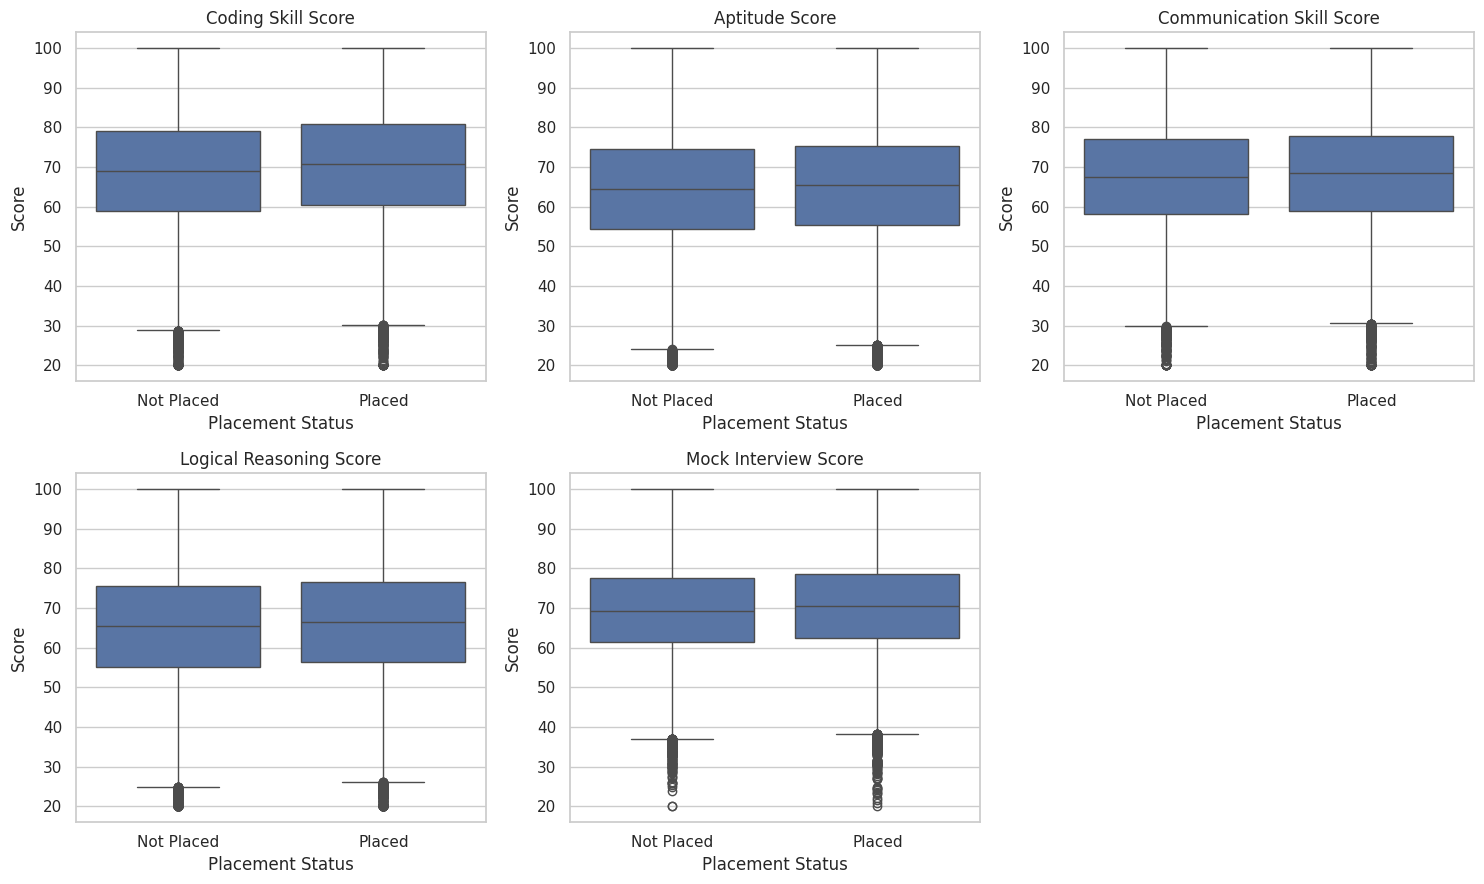

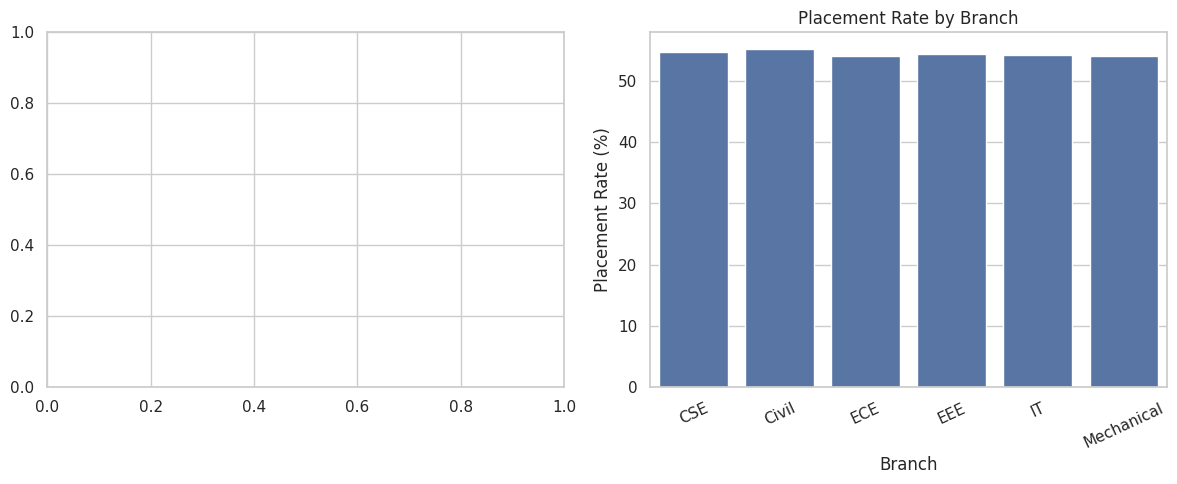

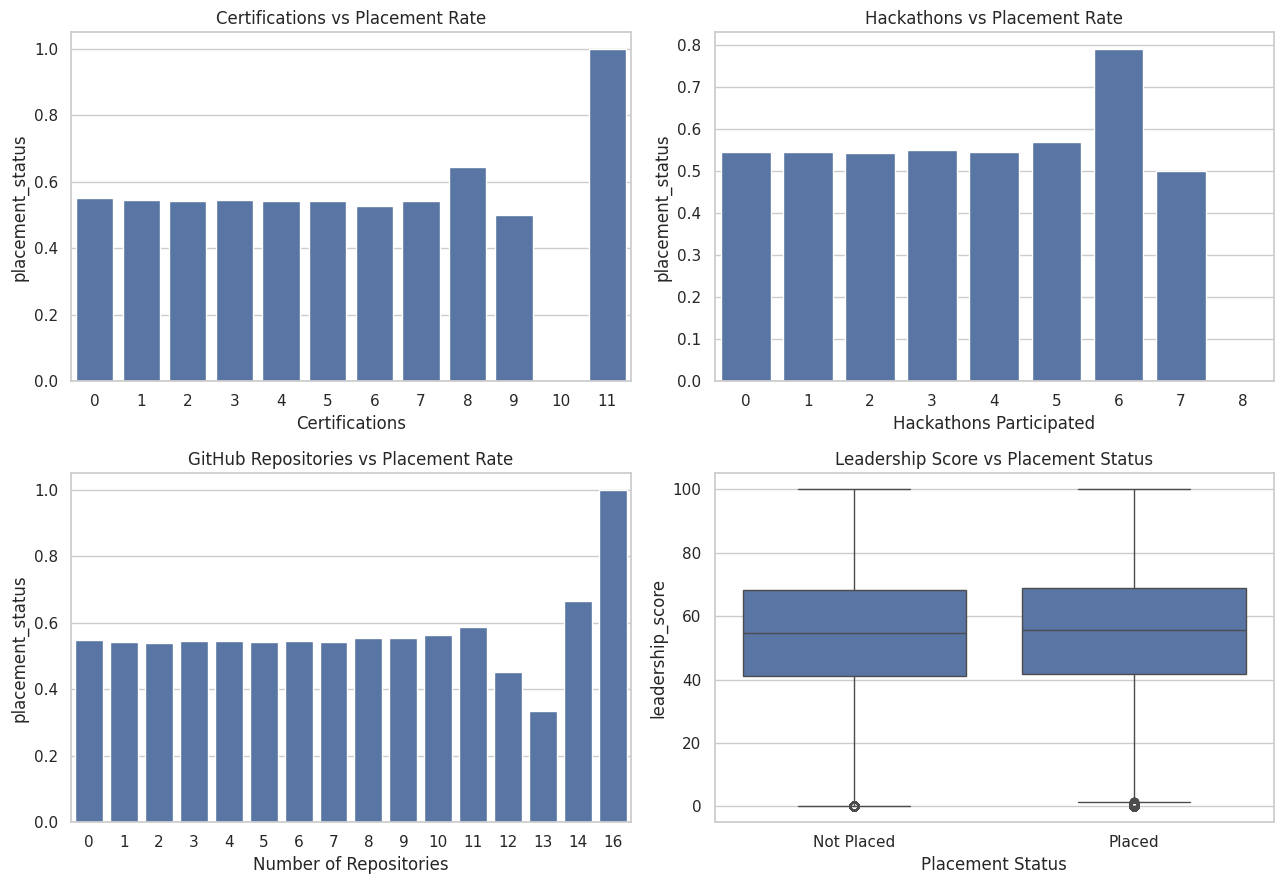

In [ ]:
sns.set_theme(style="whitegrid")
print("Dataset shape:", df.shape)
print("\nPlacement distribution:", df["placement_status"].value_counts())

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="placement_status", y="cgpa")
plt.title("CGPA vs Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("CGPA")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="placement_status",
    y="attendance_percentage")
plt.title("Attendance Percentage vs Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Attendance (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
sns.barplot(
    data=df,
    x="backlogs",
    y=df["placement_status"].eq("Placed").astype(int),
    errorbar=None)
plt.title("Backlogs vs Placement Rate")
plt.xlabel("Number of Backlogs")
plt.ylabel("Placement Rate")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(
    data=df, x="internships_count",
    y=df["placement_status"].eq("Placed").astype(int),
    errorbar=None, ax=axes[0])
axes[0].set_title("Internships vs Placement Rate")
axes[0].set_xlabel("Number of Internships")
axes[0].set_ylabel("Placement Rate")
sns.barplot(
    data=df, x="projects_count",
    y=df["placement_status"].eq("Placed").astype(int),
    errorbar=None, ax=axes[1])
axes[1].set_title("Projects vs Placement Rate")
axes[1].set_xlabel("Number of Projects")
axes[1].set_ylabel("Placement Rate")
plt.tight_layout()
plt.show()

skill_columns = [
    "coding_skill_score",
    "aptitude_score",
    "communication_skill_score",
    "logical_reasoning_score",
    "mock_interview_score"]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for i, col in enumerate(skill_columns):
    sns.boxplot( data=df, x="placement_status", y=col, ax=axes[i])
    axes[i].set_title(f"{col.replace('_', ' ').title()}")
    axes[i].set_xlabel("Placement Status")
    axes[i].set_ylabel("Score")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col, title in [(axes[0], "college_tier", "Placement Rate by College Tier"),
 (axes[1], "branch", "Placement Rate by Branch")]:
 rates = (df.assign(placed=df["placement_status"].eq("Placed"))
    .groupby(col, observed=True)["placed"]
          .mean()
          .mul(100)
          .reset_index(name="placement_rate"))
sns.barplot(data=rates, x=col, y="placement_rate",
            errorbar=None, ax=ax)
ax.set_title(title)
ax.set_xlabel(col.replace("_", " ").title())
ax.set_ylabel("Placement Rate (%)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.barplot(
    data=df, x="certifications_count",
    y=df["placement_status"].eq("Placed").astype(int),
    errorbar=None, ax=axes[0, 0])
axes[0, 0].set_title("Certifications vs Placement Rate")
axes[0, 0].set_xlabel("Certifications")
sns.barplot(
    data=df, x="hackathons_participated",
    y=df["placement_status"].eq("Placed").astype(int),
    errorbar=None, ax=axes[0, 1])
axes[0, 1].set_title("Hackathons vs Placement Rate")
axes[0, 1].set_xlabel("Hackathons Participated")
sns.barplot(
    data=df, x="github_repos",
    y=df["placement_status"].eq("Placed").astype(int),
    errorbar=None, ax=axes[1, 0])
axes[1, 0].set_title("GitHub Repositories vs Placement Rate")
axes[1, 0].set_xlabel("Number of Repositories")
sns.boxplot(
    data=df, x="placement_status",
    y="leadership_score", ax=axes[1, 1])
axes[1, 1].set_title("Leadership Score vs Placement Status")
axes[1, 1].set_xlabel("Placement Status")
plt.tight_layout()
plt.show()




TASK 5: Feature Relationship and Correlation Analysis

Analyze the relationships between the numerical features in the dataset. Create a
correlation analysis and identify which student characteristics have stronger
relationships with placement outcomes. Pay special attention to CGPA, coding skill
score, aptitude score, communication skill score, logical reasoning score, mock
interview score, internships, projects, backlogs, attendance, and study hours.

Compare the correlation results with the observations from exploratory analysis and
explain why correlation alone should not be treated as proof that a particular feature
causes placement success.


Target encoding:
placement_binary
1    54459
0    45541
Name: count, dtype: int64
Correlation with Placement Status:
internships_count            0.0635
projects_count               0.0610
coding_skill_score           0.0508
mock_interview_score         0.0461
logical_reasoning_score      0.0363
communication_skill_score    0.0322
aptitude_score               0.0317
cgpa                         0.0121
study_hours_per_day         -0.0014
attendance_percentage       -0.0084
backlogs                    -0.0824
Name: placement_binary, dtype: float64


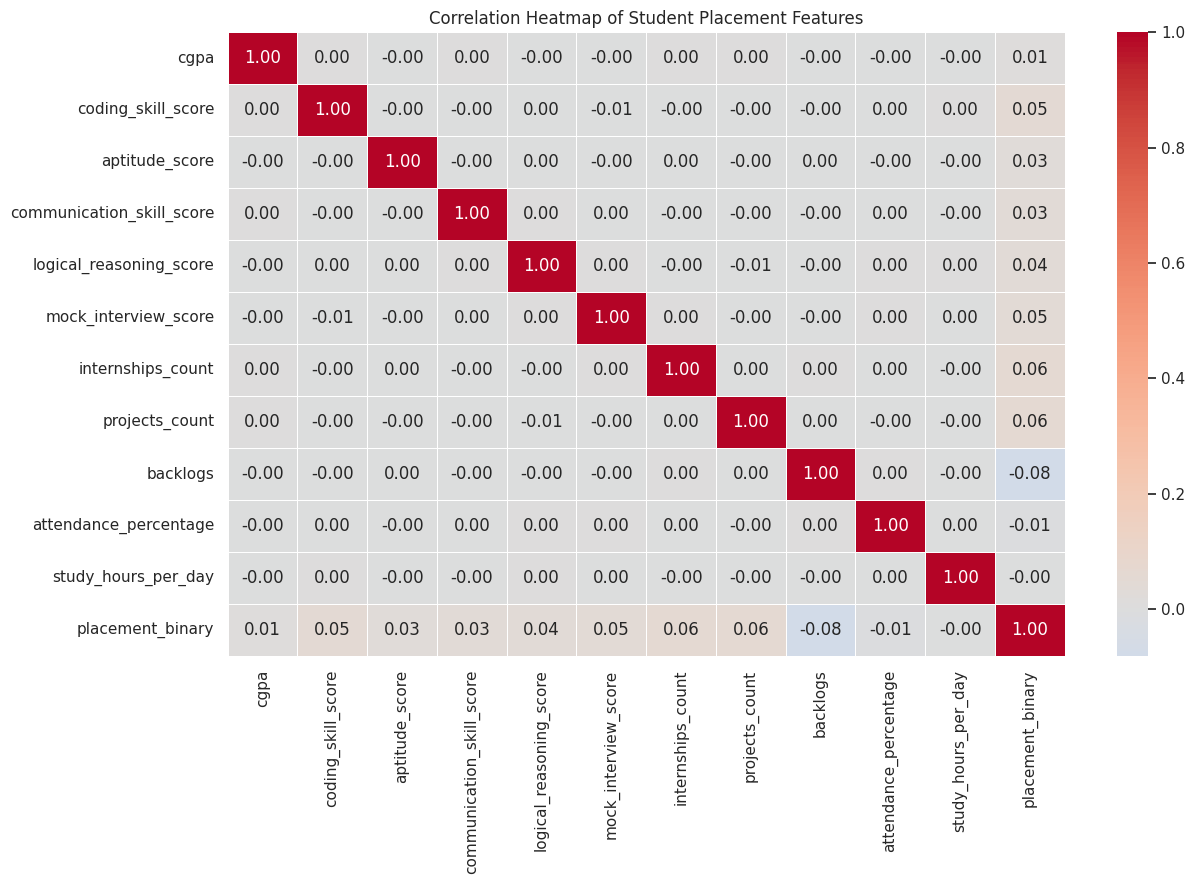

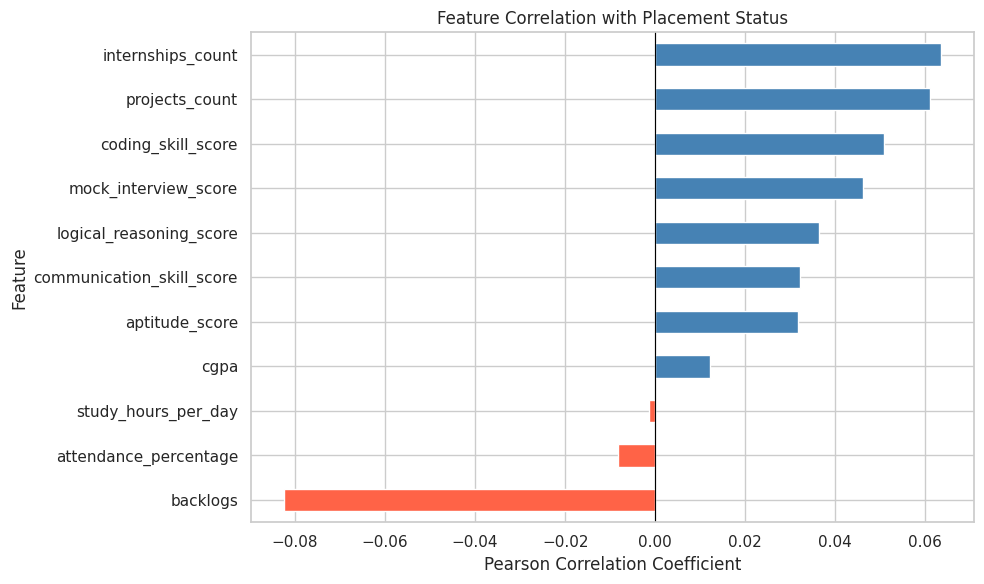

In [ ]:
df["placement_binary"] = (
    df["placement_status"]
    .map({"Not Placed": 0, "Placed": 1}))
features = [
    "cgpa",
    "coding_skill_score",
    "aptitude_score",
    "communication_skill_score",
    "logical_reasoning_score",
    "mock_interview_score",
    "internships_count",
    "projects_count",
    "backlogs",
    "attendance_percentage",
    "study_hours_per_day"]
print("\nTarget encoding:")
print(df["placement_binary"].value_counts())
correlations = (
    df[features + ["placement_binary"]]
    .corr(numeric_only=True)["placement_binary"]
    .drop("placement_binary")
    .sort_values(ascending=False))
print("Correlation with Placement Status:")
print(correlations.round(4))
corr_matrix = df[
    features + ["placement_binary"]
].corr(numeric_only=True)
plt.figure(figsize=(13, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5)
plt.title("Correlation Heatmap of Student Placement Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
correlations.sort_values().plot(
    kind="barh",
    color=[
        "tomato" if value < 0 else "steelblue"
        for value in correlations.sort_values()])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Feature Correlation with Placement Status")
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

TASK 6: Categorical Feature Analysis

Analyze the categorical features such as gender, branch, college tier, and volunteer
experience.

Compare placement outcomes across different categories and
determine whether students from different branches or college tiers have noticeably
different placement rates. Analyze whether volunteer experience appears to have
any relationship with placement.

Explain why categorical variables cannot always be
directly provided to Machine Learning algorithms and describe how they should be
converted into numerical representations.

   gender branch college_tier volunteer_experience placement_status
0    Male     IT       Tier 2                  Yes       Not Placed
1    Male    CSE       Tier 2                   No       Not Placed
2  Female    EEE       Tier 1                   No           Placed
3    Male    CSE       Tier 1                  Yes       Not Placed
4  Female     IT       Tier 3                   No           Placed

GENDER ANALYSIS
placement_status  Not Placed  Placed  Total  Placement Rate (%)
gender                                                         
Female                 18234   21738  39972               54.38
Male                   27307   32721  60028               54.51

BRANCH ANALYSIS
placement_status  Not Placed  Placed  Total  Placement Rate (%)
branch                                                         
CSE                    15792   19026  34818               54.64
Civil                   4492    5529  10021               55.17
ECE                     6842    8066  14908   

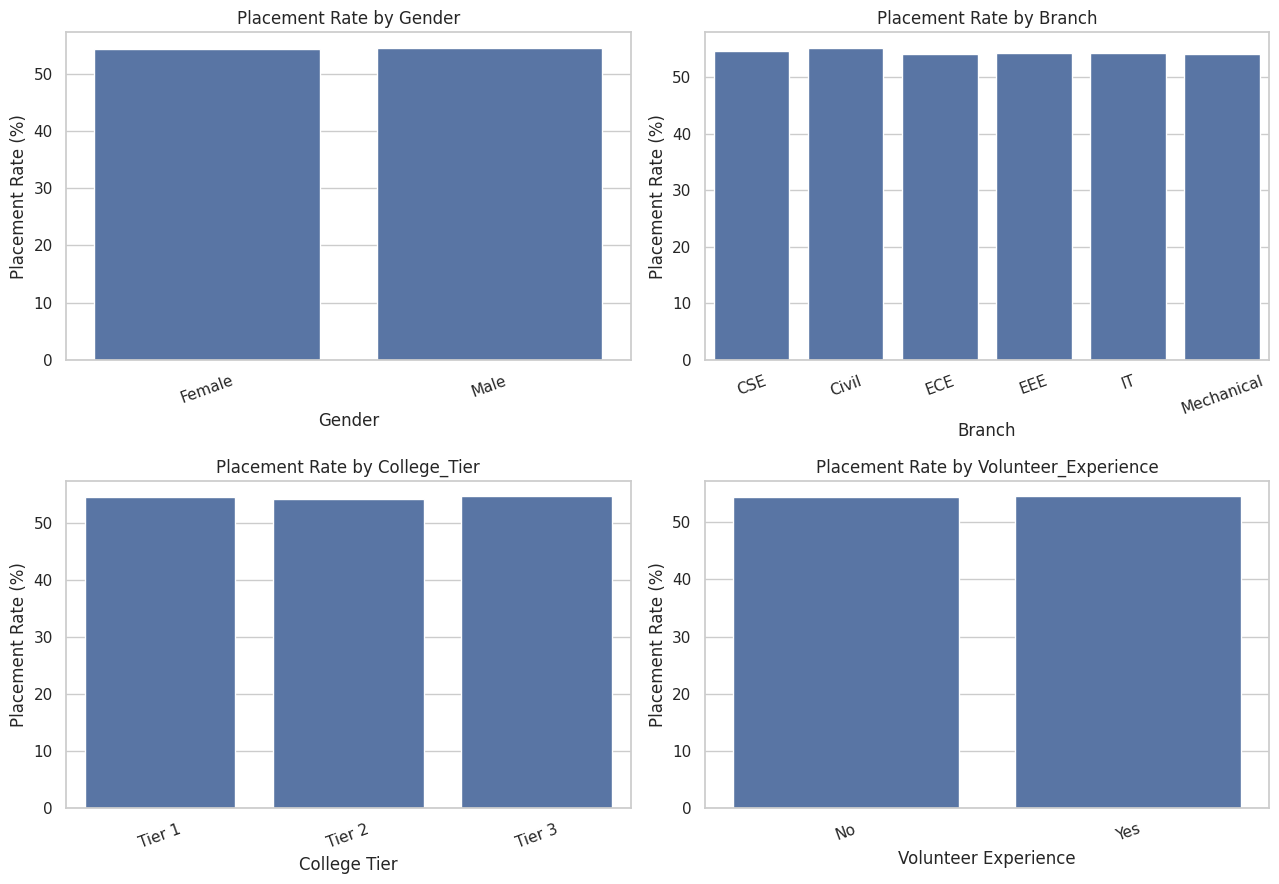


Feature: gender
Chi-square statistic: 0.15
P-value: 0.6988
No statistically significant association detected.

Feature: branch
Chi-square statistic: 4.15
P-value: 0.5279
No statistically significant association detected.

Feature: college_tier
Chi-square statistic: 1.46
P-value: 0.4828
No statistically significant association detected.

Feature: volunteer_experience
Chi-square statistic: 0.15
P-value: 0.6998
No statistically significant association detected.


In [ ]:
sns.set_theme(style="whitegrid")
categorical_features = [
    "gender",
    "branch",
    "college_tier",
    "volunteer_experience"]
print(df[categorical_features + ["placement_status"]].head())

for feature in categorical_features:
    summary = pd.crosstab(df[feature], df["placement_status"])
    summary["Total"] = summary.sum(axis=1)
    summary["Placement Rate (%)"] = (summary.get("Placed", 0) / summary["Total"] * 100).round(2)
    print(f"\n{feature.upper()} ANALYSIS")
    print(summary)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, feature in zip(axes.flatten(), categorical_features):
    placement_rate = (df.assign(
            placed=df["placement_status"].eq("Placed").astype(int))
        .groupby(feature, observed=True)["placed"]
        .mean()
        .mul(100)
        .reset_index(name="Placement Rate"))
    sns.barplot(
        data=placement_rate,
        x=feature,
        y="Placement Rate",
        ax=ax)
    ax.set_title(f"Placement Rate by {feature.title()}")
    ax.set_ylabel("Placement Rate (%)")
    ax.set_xlabel(feature.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

for feature in categorical_features:
    table = pd.crosstab(df[feature], df["placement_status"])
    chi2, p_value, dof, expected = chi2_contingency(table)
    print(f"\nFeature: {feature}")
    print(f"Chi-square statistic: {chi2:.2f}")
    print(f"P-value: {p_value:.4f}")
    if p_value < 0.05:
        print("Statistically significant association detected.")
    else:
        print("No statistically significant association detected.")


TASK 7: Feature and Target Separation

Separate the dataset into input features and the target variable. The input features
should contain the information available before the placement decision, while
placement_status should be used as the target. Make sure student_id and
salary_package_lpa are excluded from the input features.

Explain why including the
target variable or post-placement information in the input data can result in an
unrealistic Machine Learning model.

In [ ]:
X = df.drop(columns=['student_id', 'salary_package_lpa', 'placement_status'])
y = df['placement_status']
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)
print("\nInput features:", X.head())
print("\nTarget variable:", y.head())
print("\nStudent ID included in X:", 'student_id' in X.columns)
print("Salary package included in X:", 'salary_package_lpa' in X.columns)


Input features shape: (100000, 24)
Target variable shape: (100000,)

Input features:    age  gender  cgpa branch college_tier  internships_count  projects_count  \
0   24    Male  7.53     IT       Tier 2                  4               6   
1   21    Male  7.92    CSE       Tier 2                  1               3   
2   22  Female  8.60    EEE       Tier 1                  0               1   
3   24    Male  6.68    CSE       Tier 1                  0               2   
4   20  Female  8.43     IT       Tier 3                  1               4   

   certifications_count  coding_skill_score  aptitude_score  ...  \
0                     1           99.238568       81.707722  ...   
1                     6           80.966123       63.116715  ...   
2                     1           49.177184       48.658753  ...   
3                     2           79.359084       66.376653  ...   
4                     3           65.018573       61.274985  ...   

   linkedin_connections  mock_i

TASK 8: Train-Test Split

Divide the dataset into training and testing datasets using an 80:20 ratio and
random_state 42. Maintain the proportion of placed and not-placed students while
splitting the data.

 Explain why the model should be tested on data that it has never
seen during training.

 Also explain overfitting and describe how an overfitted
placement prediction model could give misleadingly high results.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)
print("\nTraining placement distribution:", y_train.value_counts(normalize=True) * 100)

Training features shape: (80000, 24)
Testing features shape: (20000, 24)
Training target shape: (80000,)
Testing target shape: (20000,)

Training placement distribution: placement_status
Placed        54.45875
Not Placed    45.54125
Name: proportion, dtype: float64


TASK 9: Feature Encoding and Scaling

Prepare the numerical and categorical features for Machine Learning. Encode
categorical variables such as gender, branch, college tier, and volunteer experience
using an appropriate encoding technique.

Apply feature scaling to numerical
variables where required, particularly for algorithms that are sensitive to differences
in feature ranges.

Explain why CGPA, LinkedIn connections, study hours, skill
scores, and other variables can exist on very different scales and why scaling is
particularly important for models based on distance or mathematical boundaries.

In [ ]:
onehot_cols = ['gender', 'branch', 'volunteer_experience']
ordinal_cols = ['college_tier']
numeric_cols = [
    col for col in X_train.select_dtypes(include='number').columns
    if col not in ordinal_cols]
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('nominal', OneHotEncoder(handle_unknown='ignore'),
         onehot_cols),
        ('ordinal', OrdinalEncoder(
            categories=[['Tier 1', 'Tier 2', 'Tier 3']]
        ), ordinal_cols)
    ],
    remainder='drop')
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("\nPreprocessing completed successfully.")


Training data shape: (80000, 31)
Testing data shape: (20000, 31)

Preprocessing completed successfully.


TASK 10: Model Training

Train at least four different Machine Learning models to predict student placement.
Use Logistic Regression, Random Forest, Support Vector Machine, and K-Nearest
Neighbors. Train each model using the prepared training dataset and generate
predictions on the testing dataset.

Briefly explain how each algorithm makes its
predictions and identify which models are expected to benefit from feature scaling.

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Support Vector Machine": SVC(kernel='rbf', random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)}
trained_models = {}
predictions = {}
results = []
for name, model in models.items():
    print(f"\nTraining {name} ")
    model.fit(X_train_processed, y_train)
    y_pred = model.predict(X_test_processed)
    trained_models[name] = model
    predictions[name] = y_pred
    accuracy = accuracy_score(y_test, y_pred)
    results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy * 100, 2)})
    print("Test Accuracy:", round(accuracy * 100, 2), "%")
    print("Sample predictions:", y_pred[:10])
results_df = pd.DataFrame(results)
print("\nModel Training Summary:")
print(results_df.sort_values( by="Test Accuracy (%)", ascending=False).to_string(index=False))



Training Logistic Regression 
Test Accuracy: 100.0 %
Sample predictions: ['Not Placed' 'Not Placed' 'Not Placed' 'Placed' 'Placed' 'Not Placed'
 'Placed' 'Placed' 'Not Placed' 'Not Placed']

Training Random Forest 
Test Accuracy: 100.0 %
Sample predictions: ['Not Placed' 'Not Placed' 'Not Placed' 'Placed' 'Placed' 'Not Placed'
 'Placed' 'Placed' 'Not Placed' 'Not Placed']

Training Support Vector Machine 
Test Accuracy: 100.0 %
Sample predictions: ['Not Placed' 'Not Placed' 'Not Placed' 'Placed' 'Placed' 'Not Placed'
 'Placed' 'Placed' 'Not Placed' 'Not Placed']

Training K-Nearest Neighbors 
Test Accuracy: 99.92 %
Sample predictions: ['Not Placed' 'Not Placed' 'Not Placed' 'Placed' 'Placed' 'Not Placed'
 'Placed' 'Placed' 'Not Placed' 'Not Placed']

Model Training Summary:
                 Model  Test Accuracy (%)
   Logistic Regression             100.00
         Random Forest             100.00
Support Vector Machine             100.00
   K-Nearest Neighbors              99.92


TASK 11: Model Evaluation and Comparison

Evaluate the performance of all trained models using accuracy, precision, recall, and
F1-score. Create a comparison between the models and determine which algorithm
provides the best overall performance. Pay particular attention to recall for the Not
Placed and Placed classes because an educational institution may want to identify
students who are at risk of remaining unplaced.

 Explain why accuracy alone may not
be sufficient when evaluating a placement prediction system.


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

  Not Placed       1.00      1.00      1.00      9108
      Placed       1.00      1.00      1.00     10892

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



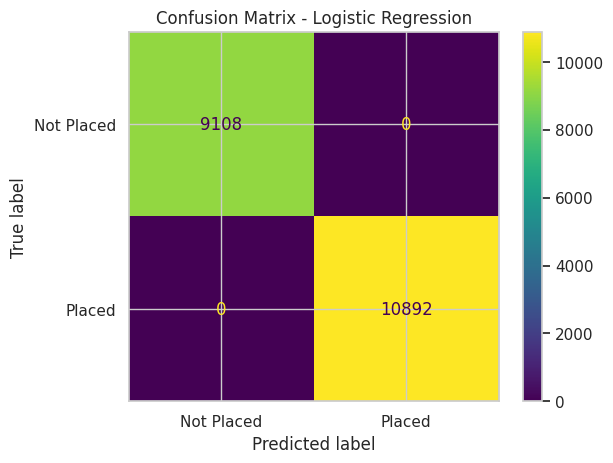


Model: Random Forest

Classification Report:
              precision    recall  f1-score   support

  Not Placed       1.00      1.00      1.00      9108
      Placed       1.00      1.00      1.00     10892

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



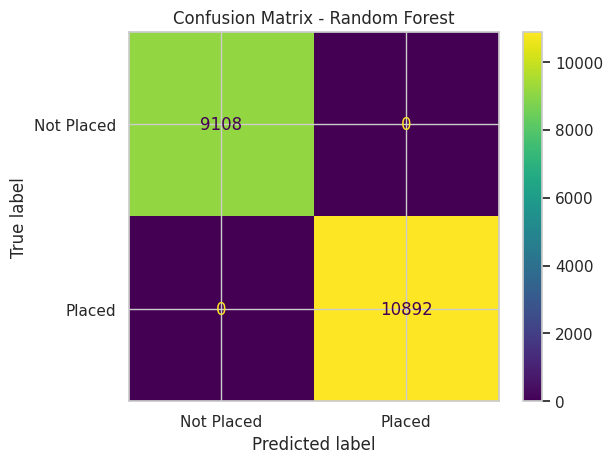


Model: Support Vector Machine

Classification Report:
              precision    recall  f1-score   support

  Not Placed       1.00      1.00      1.00      9108
      Placed       1.00      1.00      1.00     10892

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



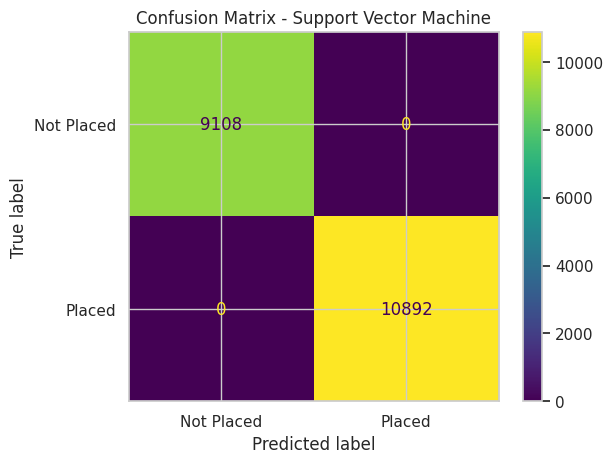


Model: K-Nearest Neighbors

Classification Report:
              precision    recall  f1-score   support

  Not Placed       1.00      1.00      1.00      9108
      Placed       1.00      1.00      1.00     10892

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



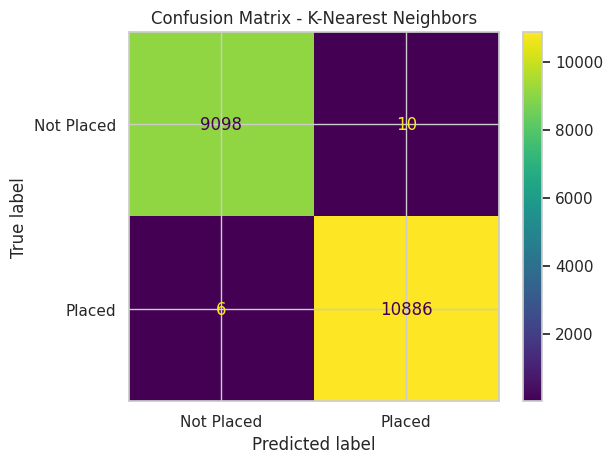


Model Comparison:                  Model  Accuracy (%)  Precision (Placed) (%)  Recall (Placed) (%)  Recall (Not Placed) (%)  F1-score (Placed) (%)  Weighted F1-score (%)
   Logistic Regression        100.00                  100.00               100.00                   100.00                 100.00                 100.00
         Random Forest        100.00                  100.00               100.00                   100.00                 100.00                 100.00
Support Vector Machine        100.00                  100.00               100.00                   100.00                 100.00                 100.00
   K-Nearest Neighbors         99.92                   99.91                99.94                    99.89                  99.93                  99.92

Best Overall Model: Logistic Regression
Weighted F1-score: 100.0 %
Recall for Not Placed: 100.0 %

Best Model for Identifying At-Risk Students: Logistic Regression
Not Placed Recall: 100.0 %


In [ ]:
results = []
for name, model in trained_models.items():
    y_pred = predictions[name]
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, pos_label="Placed", zero_division=0)
    recall = recall_score(
        y_test, y_pred, pos_label="Placed", zero_division=0)
    f1 = f1_score(
        y_test, y_pred, pos_label="Placed", zero_division=0)
    report = classification_report(
        y_test,
        y_pred,
        labels=["Not Placed", "Placed"],
        output_dict=True,
        zero_division=0)
    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Precision (Placed) (%)": round(precision * 100, 2),
        "Recall (Placed) (%)": round(recall * 100, 2),
        "Recall (Not Placed) (%)": round(
            report["Not Placed"]["recall"] * 100, 2),
        "F1-score (Placed) (%)": round(f1 * 100, 2),
        "Weighted F1-score (%)": round(report["weighted avg"]["f1-score"] * 100, 2)
    })
    print(f"\n{'=' * 55}")
    print(f"Model: {name}")
    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        labels=["Not Placed", "Placed"],
        zero_division=0))
    cm = confusion_matrix(
        y_test, y_pred,
        labels=["Not Placed", "Placed"])
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Placed", "Placed"])
    display.plot(values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()
comparison_df = pd.DataFrame(results)
comparison_df = comparison_df.sort_values(by="Weighted F1-score (%)", ascending=False)
print("\nModel Comparison:", comparison_df.to_string(index=False))
best_model = comparison_df.iloc[0]
print("\nBest Overall Model:", best_model["Model"])
print("Weighted F1-score:", best_model["Weighted F1-score (%)"], "%")
print("Recall for Not Placed:", best_model["Recall (Not Placed) (%)"], "%")
best_at_risk = comparison_df.loc[comparison_df["Recall (Not Placed) (%)"].idxmax()]
print("\nBest Model for Identifying At-Risk Students:", best_at_risk["Model"])
print("Not Placed Recall:", best_at_risk["Recall (Not Placed) (%)"], "%")


TASK 12: Confusion Matrix Analysis

Generate a confusion matrix for the best-performing model and analyze the
prediction errors.

Identify how many placed students were correctly identified, how
many not-placed students were correctly identified, and where the model made
incorrect predictions.

Explain the difference between false positives and false
negatives in the context of student placement and determine

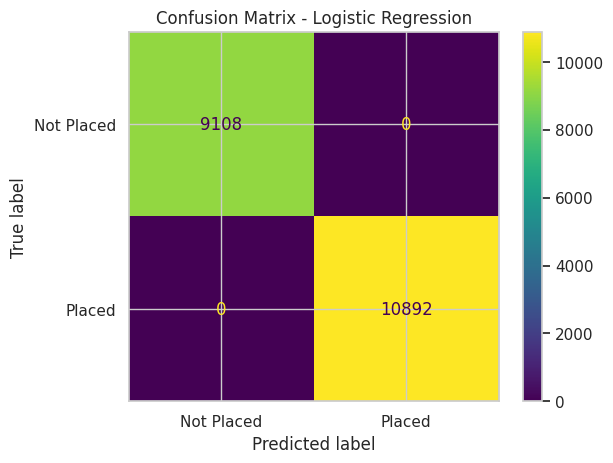

Best-performing model: Logistic Regression

Confusion Matrix:
[[ 9108     0]
 [    0 10892]]

Prediction Analysis:
Placed students correctly identified: 10892
Not Placed students correctly identified: 9108
Not Placed predicted as Placed: 0
Placed predicted as Not Placed: 0
Total incorrect predictions: 0
False Positives: 0
False Negatives: 0


In [ ]:
best_model_name = comparison_df.loc[
    comparison_df["Weighted F1-score (%)"].idxmax(), "Model"]
y_pred_best = predictions[best_model_name]
labels = ["Not Placed", "Placed"]
cm = confusion_matrix(y_test, y_pred_best, labels=labels)
correct_not_placed = cm[0, 0]
incorrect_not_placed_as_placed = cm[0, 1]
incorrect_placed_as_not_placed = cm[1, 0]
correct_placed = cm[1, 1]
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels)
display.plot(values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()
print("Best-performing model:", best_model_name)
print("\nConfusion Matrix:")
print(cm)
print("\nPrediction Analysis:")
print("Placed students correctly identified:", correct_placed)
print("Not Placed students correctly identified:", correct_not_placed)
print("Not Placed predicted as Placed:", incorrect_not_placed_as_placed)
print("Placed predicted as Not Placed:", incorrect_placed_as_not_placed)
print("Total incorrect predictions:", incorrect_not_placed_as_placed + incorrect_placed_as_not_placed)

false_positives = cm[1, 0]
false_negatives = cm[0, 1]

print("False Positives:", false_positives)
print("False Negatives:", false_negatives)


TASK 13: Feature Importance Analysis

Use an appropriate model such as Random Forest to analyze feature importance.
Identify which student characteristics contribute most to placement prediction.

Compare the importance of CGPA, coding skill, aptitude, communication ability,
internships, projects, mock interview performance, backlogs, college tier,
certifications, and other features.

 Determine whether the model&#39;s most important
features match the patterns discovered during exploratory data analysis.

Feature Importance Ranking:
                  Feature  Importance  Importance (%)
         placement_binary    0.934682           93.47
       coding_skill_score    0.004878            0.49
     mock_interview_score    0.004505            0.45
  logical_reasoning_score    0.004423            0.44
communication_skill_score    0.004158            0.42
           aptitude_score    0.004033            0.40
         leadership_score    0.003894            0.39
    extracurricular_score    0.003853            0.39
                     cgpa    0.003629            0.36
     linkedin_connections    0.003564            0.36
    attendance_percentage    0.003560            0.36
                 backlogs    0.003328            0.33
      study_hours_per_day    0.003155            0.32
              sleep_hours    0.003116            0.31
           projects_count    0.002659            0.27
        internships_count    0.002151            0.22
                   branch    0.002054            0.21


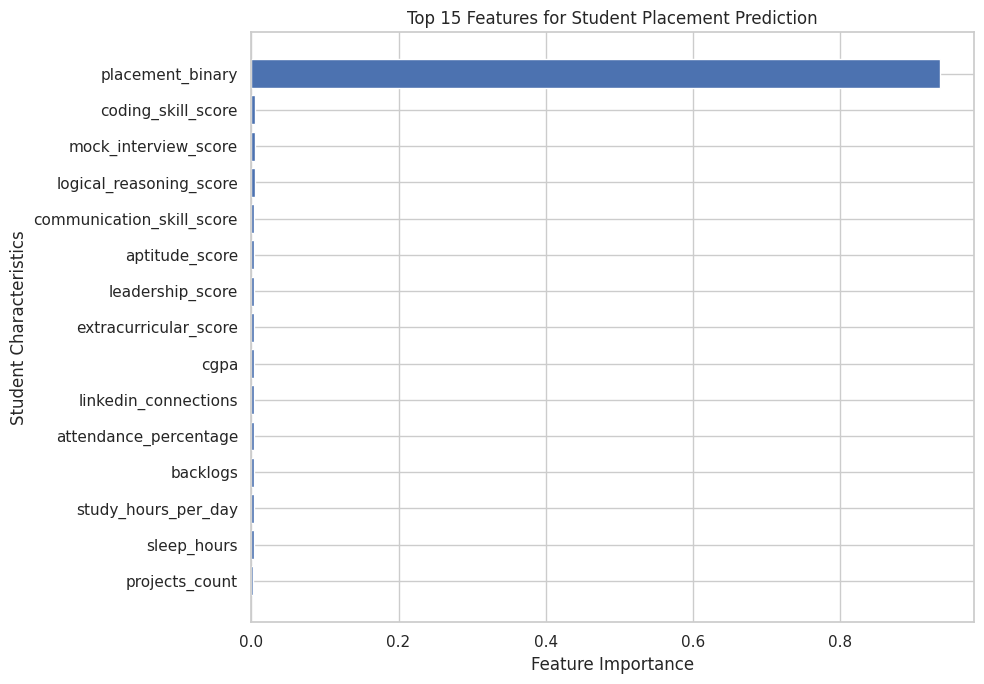

In [ ]:
if "Random Forest" in trained_models:
    rf_model = trained_models["Random Forest"]
else:
    rf_model = RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1)
    rf_model.fit(X_train_processed, y_train)
feature_names = preprocessor.get_feature_names_out()
importance_values = rf_model.feature_importances_
importance_df = pd.DataFrame({
    "Encoded Feature": feature_names,
    "Importance": importance_values})
def original_feature(encoded_name):
    name = encoded_name.split("__", 1)[-1]
    for col in onehot_cols:
        if name == col or name.startswith(col + "_"):
            return col
    return name
importance_df["Original Feature"] = (
    importance_df["Encoded Feature"].apply(original_feature))
grouped_importance = (
    importance_df.groupby("Original Feature")["Importance"]
    .sum()
    .sort_values(ascending=False))
ranking = grouped_importance.reset_index()
ranking.columns = ["Feature", "Importance"]
ranking["Importance (%)"] = ( ranking["Importance"] * 100).round(2)
print("Feature Importance Ranking:")
print(ranking.to_string(index=False))
key_features = [
    "cgpa",
    "coding_skill_score",
    "aptitude_score",
    "communication_skill_score",
    "logical_reasoning_score",
    "internships_count",
    "projects_count",
    "mock_interview_score",
    "backlogs",
    "college_tier",
    "certifications_count",
    "hackathons_participated",
    "github_repos",
    "linkedin_connections",
    "attendance_percentage",
    "study_hours_per_day",
    "extracurricular_score",
    "leadership_score",
    "volunteer_experience",
    "age",
    "gender",
    "branch",
    "sleep_hours"
]
comparison = ranking[
    ranking["Feature"].isin(key_features)
].sort_values("Importance", ascending=False)
print("\nImportance of Selected Student Characteristics:")
print(comparison.to_string(index=False))
top_features = ranking.head(15).sort_values("Importance", ascending=True)
plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Student Characteristics")
plt.title("Top 15 Features for Student Placement Prediction")
plt.tight_layout()
plt.show()

TASK 14: Model Improvement

Take the best-performing model and attempt to improve its performance. Experiment
with suitable model parameters and compare the original model with the improved
version.

Analyze whether the changes actually improve performance on unseen
testing data.

Explain why increasing model complexity does not always guarantee
better real-world performance.

In [ ]:
best_model_name = comparison_df.loc[
    comparison_df["Weighted F1-score (%)"].idxmax(), "Model"]
original_model = trained_models[best_model_name]
print("Original Best Model:", best_model_name)
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10],
        "class_weight": [None, "balanced"]},
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
        "max_features": ["sqrt"]},
    "Support Vector Machine": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]},
    "K-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7],
        "weights": ["uniform", "distance"],
        "p": [1, 2]}}
cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=original_model,
    param_grid=param_grids[best_model_name],
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True)
grid_search.fit(X_train_processed, y_train)
improved_model = grid_search.best_estimator_
print("\nBest Parameters:", grid_search.best_params_)
print("Best Cross-Validation Weighted F1:", round(grid_search.best_score_, 4))
def evaluate_model(model, X_test, y_test):
    pred = model.predict(X_test)
    return {
        "Accuracy (%)": round(
            accuracy_score(y_test, pred) * 100, 2
        ),
        "Precision (Placed) (%)": round(
            precision_score(
                y_test, pred, pos_label="Placed",
                zero_division=0
            ) * 100, 2
        ),
        "Recall (Placed) (%)": round(
            recall_score(
                y_test, pred, pos_label="Placed",
                zero_division=0
            ) * 100, 2
        ),
        "Recall (Not Placed) (%)": round(
            recall_score(
                y_test, pred, pos_label="Not Placed",
                zero_division=0
            ) * 100, 2
        ),
        "Weighted F1-score (%)": round(
            f1_score(
                y_test, pred, average="weighted",
                zero_division=0
            ) * 100, 2
        )
    }
original_results = evaluate_model(
    original_model, X_test_processed, y_test)
improved_results = evaluate_model(
    improved_model, X_test_processed, y_test)
comparison = pd.DataFrame(
    [original_results, improved_results],
    index=["Original Model", "Improved Model"])
print("\nOriginal vs Improved Model:", comparison)
print("\nChange in Test Metrics:")
print((comparison.loc["Improved Model"] - comparison.loc["Original Model"]).round(2))
trained_models["Improved Model"] = improved_model

Original Best Model: Logistic Regression
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Best Parameters: {'C': 0.1, 'class_weight': None}
Best Cross-Validation Weighted F1: 1.0

Original vs Improved Model:                 Accuracy (%)  Precision (Placed) (%)  Recall (Placed) (%)  \
Original Model         100.0                   100.0                100.0   
Improved Model         100.0                   100.0                100.0   

                Recall (Not Placed) (%)  Weighted F1-score (%)  
Original Model                    100.0                  100.0  
Improved Model                    100.0                  100.0  

Change in Test Metrics:
Accuracy (%)               0.0
Precision (Placed) (%)     0.0
Recall (Placed) (%)        0.0
Recall (Not Placed) (%)    0.0
Weighted F1-score (%)      0.0
dtype: float64


TASK 15: Hyperparameter Tuning

Perform hyperparameter tuning using GridSearchCV or another appropriate
technique. Tune important parameters of the selected Machine Learning model and
use cross-validation to evaluate different combinations.

Identify the best parameters
and the best cross-validation score. Compare the tuned model with the original
model and determine whether hyperparameter optimization resulted in meaningful
improvement.

In [ ]:
best_model_name = comparison_df.loc[
    comparison_df["Weighted F1-score (%)"].idxmax(), "Model"]
original_model = trained_models[best_model_name]
print("Selected Model:", best_model_name)
param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10],
        "class_weight": [None],
        },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 15, 25],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
        "max_features": ["sqrt"]},
    "Support Vector Machine": {
        "C": [0.1, 1, 10],
        "kernel": ["rbf"],
        "gamma": ["scale", "auto"]},
    "K-Nearest Neighbors": {
        "n_neighbors": [3, 5, 7, 9],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    }}
cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=original_model,
    param_grid=param_grids[best_model_name],
    scoring="f1_weighted",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True)
grid_search.fit(X_train_processed, y_train)
tuned_model = grid_search.best_estimator_
print("\nBest Parameters:", grid_search.best_params_)
print("\nBest Cross-Validation Weighted F1-score:",
      round(grid_search.best_score_, 4))
def evaluate(model):
    pred = model.predict(X_test_processed)
    return {
        "Accuracy (%)": round(
            accuracy_score(y_test, pred) * 100, 2),
        "Precision (Placed) (%)": round(
            precision_score(
                y_test, pred, pos_label="Placed",
                zero_division=0
            ) * 100, 2),
        "Recall (Placed) (%)": round(
            recall_score(
                y_test, pred, pos_label="Placed",
                zero_division=0
            ) * 100, 2),
        "Recall (Not Placed) (%)": round(
            recall_score(
                y_test, pred, pos_label="Not Placed",
                zero_division=0
            ) * 100, 2),
        "Weighted F1-score (%)": round(
            f1_score(
                y_test, pred, average="weighted",
                zero_division=0
            ) * 100, 2
        )}
original_metrics = evaluate(original_model)
tuned_metrics = evaluate(tuned_model)
results = pd.DataFrame(
    [original_metrics, tuned_metrics],
    index=["Original Model", "Tuned Model"])
print("\nPerformance Comparison:", results)
print("\nChange After Tuning (percentage points):")
print((results.loc["Tuned Model"] - results.loc["Original Model"]).round(2))
trained_models["Tuned Model"] = tuned_model

Selected Model: Logistic Regression
Fitting 3 folds for each of 3 candidates, totalling 9 fits

Best Parameters: {'C': 0.1, 'class_weight': None}

Best Cross-Validation Weighted F1-score: 1.0

Performance Comparison:                 Accuracy (%)  Precision (Placed) (%)  Recall (Placed) (%)  \
Original Model         100.0                   100.0                100.0   
Tuned Model            100.0                   100.0                100.0   

                Recall (Not Placed) (%)  Weighted F1-score (%)  
Original Model                    100.0                  100.0  
Tuned Model                       100.0                  100.0  

Change After Tuning (percentage points):
Accuracy (%)               0.0
Precision (Placed) (%)     0.0
Recall (Placed) (%)        0.0
Recall (Not Placed) (%)    0.0
Weighted F1-score (%)      0.0
dtype: float64


TASK 16: Build Student Placement Prediction System

Create a prediction system that accepts information about a new student before the
placement process. The system should accept details such as CGPA, branch,
college tier, number of internships, number of projects, certifications, coding skill
score, aptitude score, communication skill score, logical reasoning score,
hackathons, GitHub repositories, LinkedIn connections, mock interview score,
attendance percentage, backlogs, extracurricular score, leadership score, volunteer
experience, sleep hours, and study hours per day.

The system should process the information in the same way as the training data and
return whether the student is predicted to be Placed or Not Placed along with the
model&#39;s prediction probability.

In [ ]:
if "Tuned Model" in trained_models:
    model = trained_models["Tuned Model"]
    model_name = "Tuned Model"
elif "Improved Model" in trained_models:
    model = trained_models["Improved Model"]
    model_name = "Improved Model"
else:
    model_name = comparison_df.loc[
        comparison_df["Weighted F1-score (%)"].idxmax(),
        "Model"]
    model = trained_models[model_name]
print("=" * 55)
print("       STUDENT PLACEMENT PREDICTION SYSTEM")
print("=" * 55)
print("Model used:", model_name)
def get_number(prompt, minimum, maximum, integer=False):
    while True:
        try:
            value = float(input(prompt))
            if not np.isfinite(value):
                print("Please enter a valid finite number.")
                continue
            if value < minimum or value > maximum:
                print(f"Enter a value between {minimum} and {maximum}.")
                continue
            if integer:
                if not value.is_integer():
                    print("Please enter a whole number.")
                    continue
                return int(value)
            return value
        except ValueError:
            print("Invalid input. Please enter a number.")
def get_category(prompt, valid_options):
    options = {option.lower(): option for option in valid_options}
    while True:
        value = input(
            f"{prompt} ({'/'.join(valid_options)}): "
            ).strip()
        if value.lower() in options:
            return options[value.lower()]
        print("Invalid choice. Choose from:", ", ".join(valid_options))

print("\nEnter the student's details below:\n")
student = {}
student["age"] = get_number(
    "Age in years: ", 15, 100, integer=True)
student["gender"] = get_category(
    "Gender", sorted(df["gender"].dropna().astype(str).unique()))
student["cgpa"] = get_number(
    "CGPA: ", 0, 10)
student["branch"] = get_category(
    "Branch", sorted(df["branch"].dropna().astype(str).unique()))
student["college_tier"] = get_category(
    "College tier", sorted(df["college_tier"].dropna().astype(str).unique()))
student["internships_count"] = get_number(
    "Number of internships: ", 0, 100, integer=True)
student["projects_count"] = get_number(
    "Number of projects: ", 0, 100, integer=True)
student["certifications_count"] = get_number(
    "Number of certifications: ", 0, 100, integer=True)
student["coding_skill_score"] = get_number(
    "Coding skill score: ", 0, 100)
student["aptitude_score"] = get_number(
    "Aptitude score: ", 0, 100)
student["communication_skill_score"] = get_number(
    "Communication skill score: ", 0, 100)
student["logical_reasoning_score"] = get_number(
    "Logical reasoning score: ", 0, 100)
student["hackathons_participated"] = get_number(
    "Number of hackathons participated: ", 0, 100, integer=True)
student["github_repos"] = get_number(
    "Number of GitHub repositories: ", 0, 10000, integer=True)
student["linkedin_connections"] = get_number(
    "Number of LinkedIn connections: ", 0, 100000, integer=True)
student["mock_interview_score"] = get_number(
    "Mock interview score: ", 0, 100)
student["attendance_percentage"] = get_number(
    "Attendance percentage: ", 0, 100)
student["backlogs"] = get_number(
    "Number of backlogs: ", 0, 100, integer=True)
student["extracurricular_score"] = get_number(
    "Extracurricular score: ", 0, 100)
student["leadership_score"] = get_number(
    "Leadership score: ", 0, 100)
student["volunteer_experience"] = get_category(
    "Volunteer experience",
    sorted(
        df["volunteer_experience"]
        .dropna().astype(str).unique()
    )
)
student["sleep_hours"] = get_number(
    "Average sleep hours per day: ", 0, 24)
student["study_hours_per_day"] = get_number(
    "Average study hours per day: ", 0, 24)

student_df = pd.DataFrame([student])
expected_features = [col for col in X.columns if col != 'placement_binary']
student_df = student_df[expected_features]
for col in preprocessor.feature_names_in_:
    if col not in student_df.columns:
        student_df[col] = 0
student_df = student_df[preprocessor.feature_names_in_]
student_processed = preprocessor.transform(student_df)
prediction = model.predict(student_processed)[0]
if hasattr(model, "predict_proba"):
    probabilities = model.predict_proba(student_processed)[0]
    classes = list(model.classes_)

else:
    from sklearn.calibration import CalibratedClassifierCV
    calibrated_model = CalibratedClassifierCV(
        estimator=model, cv=3, method="sigmoid")
    calibrated_model.fit(X_train_processed, y_train)
    probabilities = calibrated_model.predict_proba(
        student_processed)[0]
    classes = list(calibrated_model.classes_)
probability_dict = {
    str(label): float(probability)
    for label, probability in zip(classes, probabilities)}
print("\n" + "=" * 55)
print("              PREDICTION RESULTS")
print("=" * 55)
print("\nStudent Information:",
      for key, value in student.items():
        print(f"{key.replace('_', ' ').title()}: {value}")
print("\nPredicted Placement Status:", prediction)
print("Probability of Being Placed:",
      f"{probability_dict.get('Placed', 0) * 100:.2f}%")
print("Probability of Not Being Placed:",
      f"{probability_dict.get('Not Placed', 0) * 100:.2f}%")
print("=" * 55)
print("Note: Predictions are estimates, not guarantees.")


       STUDENT PLACEMENT PREDICTION SYSTEM
Model used: Tuned Model

Enter the student's details below:

Age in years: 21
Gender (Female/Male): Female
CGPA: 8.09
Branch (CSE/Civil/ECE/EEE/IT/Mechanical): CSE
College tier (Tier 1/Tier 2/Tier 3): tier 3
Number of internships: 3
Number of projects: 6
Number of certifications: 8
Coding skill score: 90
Aptitude score: 89
Communication skill score: 82
Logical reasoning score: 85
Number of hackathons participated: 3
Number of GitHub repositories: 5
Number of LinkedIn connections: 890
Mock interview score: 87
Attendance percentage: 89
Number of backlogs: 0
Extracurricular score: 87
Leadership score: 91
Volunteer experience (No/Yes): Yes
Average sleep hours per day: 5
Average study hours per day: 6

              PREDICTION RESULTS

Student Information:
Age: 21
Gender: Female
Cgpa: 8.09
Branch: CSE
College Tier: Tier 3
Internships Count: 3
Projects Count: 6
Certifications Count: 8
Coding Skill Score: 90.0
Aptitude Score: 89.0
Communication Skill

TASK 17: Student Placement Risk Analysis

Extend the prediction system so that it provides an additional interpretation of the
student&#39;s placement situation. Based on the prediction and probability, classify the
student into categories such as High Placement Probability, Moderate Placement
Probability, or Low Placement Probability.

Identify the major factors that may be contributing to the prediction and provide a simple explanation of which areas the
student could improve, such as coding skills, aptitude, communication, internships,
projects, or interview preparation.
The recommendations should be treated as analytical insights rather than
guaranteed outcomes.

In [ ]:
def analyze_placement_risk(student, model, preprocessor, df, X,
                           X_train_processed, y_train, ranking=None):
    student_df = pd.DataFrame([student])
    expected_features = [col for col in X.columns if col != 'placement_binary']
    student_df = student_df[expected_features]
    for col in preprocessor.feature_names_in_:
        if col not in student_df.columns:
            student_df[col] = 0
    student_df = student_df[preprocessor.feature_names_in_]
    processed_student = preprocessor.transform(student_df)
    prediction_model = model
    if not hasattr(prediction_model, "predict_proba"):
        prediction_model = CalibratedClassifierCV(
            estimator=model, cv=3, method="sigmoid")
        prediction_model.fit(X_train_processed, y_train)
    predicted_class = prediction_model.predict(processed_student)[0]
    probabilities = prediction_model.predict_proba(processed_student)[0]
    class_probabilities = {
        str(label): float(prob)
        for label, prob in zip(
            prediction_model.classes_, probabilities
        )
    }
    placed_probability = class_probabilities.get("Placed", 0.0)
    not_placed_probability = class_probabilities.get("Not Placed", 0.0)
    if placed_probability >= 0.70:
        risk_category = "High Placement Probability"
        interpretation = (
            "The model estimates a relatively high probability "
            "of placement. Continued preparation is important.")
    elif placed_probability >= 0.40:
        risk_category = "Moderate Placement Probability"
        interpretation = (
            "The model estimates a moderate probability of placement. "
            "Targeted preparation may help strengthen readiness.")
    else:
        risk_category = "Low Placement Probability"
        interpretation = (
            "The model estimates a relatively low probability of placement. "
            "Reviewing skill gaps and creating a preparation plan may help.")

    print("\n" + "=" * 60)
    print("          STUDENT PLACEMENT RISK ANALYSIS")
    print("=" * 60)
    print("\nPredicted Placement Status:", predicted_class)
    print(f"Probability of Placed: {placed_probability * 100:.2f}%")
    print(f"Probability of Not Placed: {not_placed_probability * 100:.2f}%")
    print("\nPlacement Probability Category:", risk_category)
    print(interpretation)

    if ranking is not None and not ranking.empty:
        print("\nTop Predictive Features (Overall Model):")
        top_features = ranking[ranking["Feature"] != "placement_binary"].sort_values(
            "Importance", ascending=False
        ).head(5)

        for _, row in top_features.iterrows():
            print(
                f"- {row['Feature']}: "
                f"{row['Importance']:.4f} importance")

    placed_df = df[
        df["placement_status"].astype(str).str.strip().str.lower()
        == "placed"].copy()
    improvement_features = {
        "cgpa": "Review academic subjects and strengthen core concepts.",
        "coding_skill_score": "Practice coding problems and data structures.",
        "aptitude_score": "Practice quantitative aptitude and logical questions.",
        "communication_skill_score": "Improve verbal communication and presentation skills.",
        "logical_reasoning_score": "Practice reasoning exercises and timed problem-solving.",
        "internships_count": "Seek internships or relevant practical experience.",
        "projects_count": "Build and document practical projects.",
        "certifications_count": "Consider relevant certifications that reinforce skills.",
        "mock_interview_score": "Practice mock interviews and review feedback.",
        "hackathons_participated": "Consider participating in hackathons or coding events.",
        "github_repos": "Publish well-documented projects and code on GitHub.",
        "linkedin_connections": "Develop a professional network and improve your profile.",
        "attendance_percentage": "Maintain consistent attendance and participation.",
        "extracurricular_score": "Continue developing relevant extracurricular skills.",
        "leadership_score": "Look for opportunities to demonstrate teamwork and leadership."}
    recommendations = []
    for feature, advice in improvement_features.items():
        if feature not in student or feature not in placed_df.columns:
            continue
        reference_values = pd.to_numeric(
            placed_df[feature], errors="coerce").dropna()
        if reference_values.empty:
            continue
        student_value = student[feature]
        reference_median = reference_values.median()

        try:
            student_value = float(student_value)
        except (ValueError, TypeError):
            continue

        if student_value < reference_median:
            recommendations.append({
                "Feature": feature,
                "Student Value": student_value,
                "Placed-Student Median": round(reference_median, 2),
                "Recommendation": advice
            })
    if "backlogs" in student and "backlogs" in placed_df.columns:
        backlog_values = pd.to_numeric(
            placed_df["backlogs"], errors="coerce"
        ).dropna()

        if (
            not backlog_values.empty
            and float(student["backlogs"]) > backlog_values.median()
        ):
            recommendations.append({
                "Feature": "backlogs",
                "Student Value": student["backlogs"],
                "Placed-Student Median": round(backlog_values.median(), 2),
                "Recommendation": (
                    "Prioritize clearing pending subjects and strengthening "
                    "understanding of core concepts."
                )
            })
    print("\nPersonalized Improvement Recommendations:")
    if recommendations:
        for item in recommendations:
            print(
                f"\n- {item['Feature'].replace('_', ' ').title()}"
                f"\n  Student value: {item['Student Value']}"
                f"\n  Placed-student median: {item['Placed-Student Median']}"
                f"\n  Suggestion: {item['Recommendation']}")
    else:
        print(
            "No values below the selected placed-student median "
            "benchmarks were identified among the checked features.")
    print("\n" + "=" * 60)
    print("IMPORTANT DISCLAIMER")
    print(
        "These are model estimates and descriptive comparisons, not "
        "guarantees. Median comparisons are not placement requirements, "
        "and improving a feature does not guarantee placement.")
    print("=" * 60)

    return {
        "prediction": predicted_class,
        "placed_probability": placed_probability,
        "not_placed_probability": not_placed_probability,
        "risk_category": risk_category,
        "recommendations": recommendations}

risk_result = analyze_placement_risk(
    student=student,
    model=model,
    preprocessor=preprocessor,
    df=df,
    X=X,
    X_train_processed=X_train_processed,
    y_train=y_train,
    ranking=ranking)


          STUDENT PLACEMENT RISK ANALYSIS

Predicted Placement Status: Not Placed
Probability of Placed: 0.18%
Probability of Not Placed: 99.82%

Placement Probability Category: Low Placement Probability
The model estimates a relatively low probability of placement. Reviewing skill gaps and creating a preparation plan may help.

Top Predictive Features (Overall Model):
- coding_skill_score: 0.0049 importance
- mock_interview_score: 0.0045 importance
- logical_reasoning_score: 0.0044 importance
- communication_skill_score: 0.0042 importance
- aptitude_score: 0.0040 importance

Personalized Improvement Recommendations:
No values below the selected placed-student median benchmarks were identified among the checked features.

IMPORTANT DISCLAIMER
These are model estimates and descriptive comparisons, not guarantees. Median comparisons are not placement requirements, and improving a feature does not guarantee placement.


TASK 18: Final Model Analysis

Compare all the results obtained throughout the project. Determine which features
appear to have the strongest influence on placement prediction, which Machine
Learning algorithm performed best, whether feature scaling affected different
algorithms, whether hyperparameter tuning improved the model, and which type of
students were most difficult for the model to classify correctly.

 Also discuss the
limitations of using historical student data for predicting future placement outcomes.

In [ ]:
print("=" * 65)
print("1. MODEL PERFORMANCE COMPARISON")
print("=" * 65)
print(comparison_df.to_string(index=False))
best_model_name = comparison_df.loc[
    comparison_df["Weighted F1-score (%)"].idxmax(), "Model"]
print("\nBest overall model based on weighted F1-score:", best_model_name)
recall_columns = [
    col for col in comparison_df.columns
    if "Recall" in col]
if recall_columns:
    print("\nClass-wise recall comparison:")
    print(comparison_df[["Model"] + recall_columns].to_string(index=False))
print("\n" + "=" * 65)
print("2. FEATURE IMPORTANCE")
print("=" * 65)
if "ranking" in globals():
    print(ranking.head(15).to_string(index=False))
    print("\nTop five features:")
    print(ranking.head(5)["Feature"].tolist())
else:
    print("Run Task 13 to generate the feature importance ranking.")
print("\n" + "=" * 65)
print("3. HYPERPARAMETER TUNING")
print("=" * 65)
if "grid_search" in globals():
    print("Best parameters:", grid_search.best_params_)
    print("Best CV weighted F1-score:",
          round(grid_search.best_score_, 4))
if "original_metrics" in globals() and "tuned_metrics" in globals():
    tuning_comparison = pd.DataFrame(
        [original_metrics, tuned_metrics],
        index=["Original Model", "Tuned Model"])
    print("\nTest-set comparison:")
    print(tuning_comparison)
    print("\nChange after tuning:")
    print((
        tuning_comparison.loc["Tuned Model"]
        - tuning_comparison.loc["Original Model"]).round(2))
else:
    print("Run Task 15 to compare the original and tuned models.")
print("\n" + "=" * 65)
print("4. CONFUSION MATRIX AND CLASSIFICATION DIFFICULTY")
print("=" * 65)
final_model = trained_models[best_model_name]
final_predictions = final_model.predict(X_test_processed)
labels = ["Not Placed", "Placed"]
cm = confusion_matrix(y_test, final_predictions, labels=labels)
print("\nRows = actual class; columns = predicted class")
print(pd.DataFrame(
    cm,
    index=["Actual Not Placed", "Actual Placed"],
    columns=["Predicted Not Placed", "Predicted Placed"]))

report = classification_report(
    y_test,
    final_predictions,
    labels=labels,
    output_dict=True,
    zero_division=0)
print("\nRecall for Not Placed:", round(report["Not Placed"]["recall"] * 100, 2), "%")
print("Recall for Placed:", round(report["Placed"]["recall"] * 100, 2), "%")
if report["Not Placed"]["recall"] < report["Placed"]["recall"]:
    print("\nThe Not Placed class was harder to identify.")
elif report["Placed"]["recall"] < report["Not Placed"]["recall"]:
    print("\nThe Placed class was harder to identify.")
else:
    print("\nBoth classes had equal recall.")
print("\nIncorrectly predicted Not Placed students:", cm[0, 1])
print("Incorrectly predicted Placed students:", cm[1, 0])


1. MODEL PERFORMANCE COMPARISON
                 Model  Accuracy (%)  Precision (Placed) (%)  Recall (Placed) (%)  Recall (Not Placed) (%)  F1-score (Placed) (%)  Weighted F1-score (%)
   Logistic Regression        100.00                  100.00               100.00                   100.00                 100.00                 100.00
         Random Forest        100.00                  100.00               100.00                   100.00                 100.00                 100.00
Support Vector Machine        100.00                  100.00               100.00                   100.00                 100.00                 100.00
   K-Nearest Neighbors         99.92                   99.91                99.94                    99.89                  99.93                  99.92

Best overall model based on weighted F1-score: Logistic Regression

Class-wise recall comparison:
                 Model  Recall (Placed) (%)  Recall (Not Placed) (%)
   Logistic Regression             